# Customer Intelligence Engine
## 04. RFM Customer Segmentation

### Objective

This notebook analyses customer purchasing behaviour
using Recency, Frequency and Monetary (RFM) metrics.

The goal is to identify customer groups based on
their purchase history and explore potential
customer retention and engagement strategies.

The analysis uses completed positive sales
transactions from identifiable customers.

## 1. Import Libraries

Import the libraries needed for data analysis and visualisation.

In [4]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned customer data
df = pd.read_csv("/Users/richardnguyenk/Downloads/GitHub Project/Analyse Customer /data/processed/customers_clean.csv")

# Convert invoice dates to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Preview the dataset
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


## 2. Check the analysis period

Before calculating recency, the dataset will be checked for the last record date



In [5]:
# Check the date range
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

# Check customer count
print("Unique customers:", df["Customer ID"].nunique())

First transaction: 2009-12-01 07:45:00
Last transaction: 2011-12-09 12:50:00
Unique customers: 5878


## 3. Calculate RFM Metrics

The goal is to transform the transaction-level dataset into a customer-level dataset.

Currently, one customer can appear in hundred of rows. After RFM calculation, each customer will have exactly one row.

RFM measures customer purchasing behaviour using:

- Recency: Days since the customer's last purchase
- Frequency: Number of unique purchase invoices
- Monetary: Total positive sales value

Each customer will have one row containing
their RFM measurements.

In [6]:
# Set the reference date
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference date:", reference_date)

Reference date: 2011-12-10 12:50:00


In [7]:
# Calculate RFM metrics for each customer
rfm = df.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalSales", "sum")
)

# Calculate days since the last purchase
rfm["Recency"] = (
    reference_date - rfm["LastPurchase"]
).dt.days

# Keep only the RFM columns
rfm = rfm[["Recency", "Frequency", "Monetary"]]

# Preview the results
rfm.head(10)

,Recency,Frequency,Monetary
Customer ID,,,
12346,326,12,77556.46
12347,2,8,4921.53
12348,75,5,2019.40
12349,19,4,4428.69
12350,310,1,334.40
12351,375,1,300.93
12352,36,10,2849.84
12353,204,2,406.76
12354,232,1,1079.40


In [8]:
# Check the RFM dataset
print("Total customers:", len(rfm))
print("Missing values:")
print(rfm.isnull().sum())

# Summary statistics
rfm.describe().round(2)

Total customers: 5878
Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.33,6.29,2955.90
std,209.34,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04


## 4. RFM Scoring

RFM scores are assigned from 1 to 5 based on
customer purchasing behaviour.

A higher score represents more desirable
purchasing behaviour:

- Recency: More recent purchases receive higher scores.
- Frequency: More orders receive higher scores.
- Monetary: Higher spending receives higher scores.

Quantile-based scoring is used to compare customers
relative to the rest of the customer base.

In [9]:
# Score Recency: fewer days means a higher score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Score Monetary: higher spending means a higher score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Preview the scores
rfm.head(10)

,Recency,Frequency,Monetary,R_Score,M_Score
Customer ID,,,,,
12346,326,12,77556.46,2,5
12347,2,8,4921.53,5,5
12348,75,5,2019.40,3,4
12349,19,4,4428.69,5,5
12350,310,1,334.40,2,2
12351,375,1,300.93,2,2
12352,36,10,2849.84,4,4
12353,204,2,406.76,2,2
12354,232,1,1079.40,2,3


In [10]:
# Check how many customers received each score
print("Recency Scores:")
print(rfm["R_Score"].value_counts().sort_index())

print("\nMonetary Scores:")
print(rfm["M_Score"].value_counts().sort_index())

Recency Scores:
R_Score
1    1176
2    1175
3    1176
4    1175
5    1176
Name: count, dtype: int64

Monetary Scores:
M_Score
1    1176
2    1175
3    1176
4    1175
5    1176
Name: count, dtype: int64


### Frequency Scoring

Frequency scores are assigned based on the number
of distinct purchase invoices.

Customers with the same purchase frequency receive
the same score.

The thresholds are based on the observed distribution
of customer orders.

In [11]:
# Assign Frequency scores based on number of orders
def frequency_score(orders):
    if orders == 1:
        return 1
    elif orders == 2:
        return 2
    elif orders <= 4:
        return 3
    elif orders <= 7:
        return 4
    else:
        return 5

# Apply the scoring
rfm["F_Score"] = rfm["Frequency"].apply(frequency_score)

# Check score distribution
print(rfm["F_Score"].value_counts().sort_index())

F_Score
1    1623
2     944
3    1150
4     862
5    1299
Name: count, dtype: int64


## 5. Combine RFM Scores

Each customer has received a score from 1 to 5
for Recency, Frequency and Monetary value.

The three scores will be combined into an RFM code
to summarise each customer's purchasing behaviour.

For example, an RFM code of 555 represents a customer
with high scores across all three metrics.

In [12]:
# Combine Recency, Frequency and Monetary scores
rfm["RFM_Code"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

# Display the results
rfm.head(10)

,Recency,Frequency,Monetary,R_Score,M_Score,F_Score,RFM_Code
Customer ID,,,,,,,
12346,326,12,77556.46,2,5,5,255
12347,2,8,4921.53,5,5,5,555
12348,75,5,2019.40,3,4,4,344
12349,19,4,4428.69,5,5,3,535
12350,310,1,334.40,2,2,1,212
12351,375,1,300.93,2,2,1,212
12352,36,10,2849.84,4,4,5,454
12353,204,2,406.76,2,2,2,222
12354,232,1,1079.40,2,3,1,213


## 6. Customer Segmentation

Customers are grouped into five segments based
on their Recency, Frequency and Monetary scores.

The aim is to identify different purchasing patterns
and suggest appropriate customer engagement strategies.

Each customer is assigned to one segment.

In [13]:
# Assign customer segments using RFM scores
def assign_segment(row):

    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    # Recent, frequent and high-spending
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    # Recent and frequent
    elif r >= 4 and f >= 3:
        return "Loyal Customers"

    # Less recent, but previously frequent or high-spending
    elif r <= 2 and (f >= 4 or m >= 4):
        return "At Risk"

    # Recent, but not frequent
    elif r >= 4 and f <= 2:
        return "New or Occasional"

    # Remaining customers
    else:
        return "Other Customers"


# Apply the segmentation rules
rfm["Segment"] = rfm.apply(assign_segment, axis=1)

# Count customers in each segment
rfm["Segment"].value_counts()

Segment
Other Customers      3046
Champions            1266
Loyal Customers       582
New or Occasional     503
At Risk               481
Name: count, dtype: int64

## 7. Validate Customer Segments

This section compares the purchasing behaviour
of customers across the five RFM segments.

I will examine:
- Number of customers in each segment
- Average recency
- Average purchase frequency
- Average customer spending

The goal is to check whether the segmentation
rules produce meaningful customer groups.

In [14]:
# Compare customer behaviour across segments
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
)

# Calculate each segment's share of customers
segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"] / len(rfm) * 100
)

# Display results
segment_summary.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
Segment,,,,,
At Risk,481,360.20,6.15,3129.05,8.18
Champions,1266,19.60,17.39,9303.47,21.54
Loyal Customers,582,24.50,4.03,1121.85,9.90
New or Occasional,503,27.31,1.53,839.44,8.56
Other Customers,3046,314.30,2.92,990.28,51.82


In [15]:
# Dividing Other Customers into groups with different activity levels

# Select customers in the Other Customers segment
other_customers = rfm[rfm["Segment"] == "Other Customers"]

# Count customers by Recency score
other_customers["R_Score"].value_counts().sort_index()

R_Score
1    1020
2     850
3    1176
Name: count, dtype: int64

In [16]:
# Assign customers to six RFM segments
def assign_segment(row):

    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 4 and f >= 3:
        return "Loyal Customers"

    elif r <= 2 and (f >= 4 or m >= 4):
        return "At Risk"

    elif r >= 4 and f <= 2:
        return "Recent Occasional"

    elif r == 3:
        return "Needs Attention"

    else:
        return "Inactive Low-Engagement"


# Apply the updated segmentation rules
rfm["Segment"] = rfm.apply(assign_segment, axis=1)

# Check the new segment distribution
rfm["Segment"].value_counts()

Segment
Inactive Low-Engagement    1870
Champions                  1266
Needs Attention            1176
Loyal Customers             582
Recent Occasional           503
At Risk                     481
Name: count, dtype: int64

## 8. Segment Performance Analysis

This section compares customer activity and spending
across the six RFM segments.

The objective is to understand which segments
contribute the most sales value and identify
potential customer retention opportunities.

In [17]:
# Compare purchasing behaviour across segments
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    TotalSales=("Monetary", "sum")
)

# Calculate each segment's contribution to total sales
segment_summary["Sales_Percentage"] = (
    segment_summary["TotalSales"] / rfm["Monetary"].sum() * 100
)

# Sort segments by sales contribution
segment_summary = segment_summary.sort_values(
    by="TotalSales",
    ascending=False
)

# Display the summary
segment_summary.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,TotalSales,Sales_Percentage
Segment,,,,,,
Champions,1266,19.60,17.39,9303.47,11778191.30,67.79
Needs Attention,1176,107.35,4.98,1935.06,2275628.51,13.10
At Risk,481,360.20,6.15,3129.05,1505070.73,8.66
Inactive Low-Engagement,1870,444.45,1.62,396.13,740758.53,4.26
Loyal Customers,582,24.50,4.03,1121.85,652915.32,3.76
Recent Occasional,503,27.31,1.53,839.44,422239.88,2.43


## 9. Customer Segment Visualisation

This chart compares the percentage of customers
in each segment with their contribution to total
customer-linked positive sales value.

The goal is to identify which customer groups
contribute disproportionately to sales.

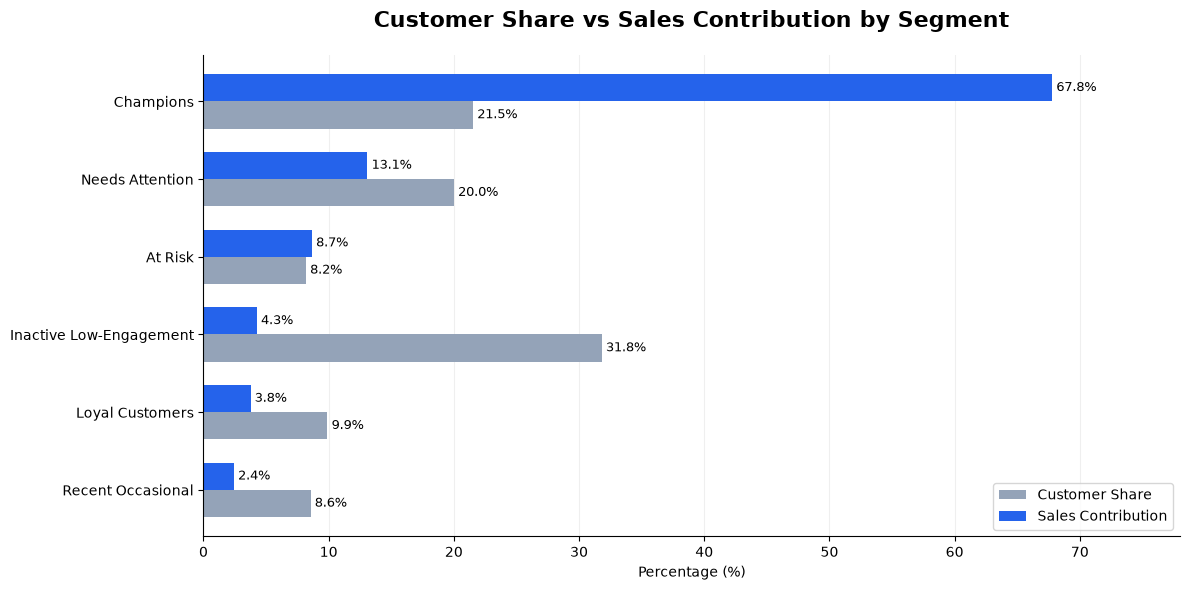

In [18]:
# Calculate each segment's percentage of customers
segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"] / len(rfm) * 100
)

# Sort segments by sales contribution
chart_data = segment_summary.sort_values(
    "Sales_Percentage",
    ascending=True
)

# Create the chart
ax = chart_data[
    ["Customer_Percentage", "Sales_Percentage"]
].plot(
    kind="barh",
    figsize=(12, 6),
    color=["#94A3B8", "#2563EB"],
    width=0.7
)

# Add chart title and labels
plt.title(
    "Customer Share vs Sales Contribution by Segment",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Percentage (%)")
plt.ylabel("")

# Rename legend
plt.legend(
    ["Customer Share", "Sales Contribution"],
    loc="lower right"
)

# Add percentage labels to each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

# Improve chart appearance
plt.xlim(0, 78)
plt.grid(axis="x", alpha=0.2)
plt.gca().set_axisbelow(True)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [28]:
rfm.to_csv("../data/processed/customer_segments.csv")

print("Customer segmentation dataset saved successfully!")

Customer segmentation dataset saved successfully!


### Key Findings — Customer Segmentation

RFM analysis identified six customer segments based on purchasing recency, frequency and spending.

The Champions segment accounted for 21.5% of customers but generated 67.8% of customer-linked positive sales value. These customers purchased frequently, spent more and remained active near the end of the observation period.

In contrast, Inactive Low-Engagement customers represented 31.8% of the customer base but contributed only 4.3% of sales.

The At Risk segment contained 481 customers who had previously demonstrated relatively strong purchasing behaviour but had not purchased recently.

### Business Recommendations

- **Champions:** Prioritise retention and maintain strong customer relationships.
- **At Risk:** Investigate declining activity and consider targeted re-engagement campaigns.
- **Needs Attention:** Monitor purchasing patterns and encourage repeat purchases.
- **Loyal Customers:** Explore opportunities to increase purchase frequency and customer spending.
- **Recent Occasional:** Encourage additional purchases through relevant product recommendations.
- **Inactive Low-Engagement:** Consider low-cost reactivation campaigns before investing in personalised outreach.

These recommendations are exploratory. Further analysis of profitability, customer acquisition dates and future purchasing behaviour would be required to evaluate their effectiveness.